# ctmc-pbee — Quickstart

This notebook is a 15-minute guided tour of **ctmc-pbee**, the code accompanying

> C. Nardin, S. Marelli, B. Sudret, M. Broccardo. *A Generalized Framework for
> Performance-Based Earthquake Engineering: Integrated Assessment of Structural
> Reliability and Resilience.* Structural Safety (under review).

You will:

1. build the continuous-time Markov chain (CTMC) of a structure from four rates;
2. compute its **reliability** (failure probability $F_\mathcal{T}$, index $\beta$);
3. compute its **resilience** (metric $\mathcal{R}_0$, index $\rho$);
4. see how the **recovery time** influences jointly resilience and reliability;
5. repeat the analysis on the **case study** of the paper (braced frame vs base-isolated building).

**Before you start:** activate the environment (`conda activate ctmc-pbee`) and select
the kernel *Python (ctmc-pbee)*. See the README for the installation.

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from ctmc_pbee import core as ct         # reliability & resilience (Eq. 8-27)
from ctmc_pbee import generator          # Q matrices from hazard + fragilities
from ctmc_pbee.paths import DATA, require_data  # <repo>/data

## 1. The model

The structure is described by three damage states:

| State | Meaning |
|---|---|
| $ds_0$ | undamaged (fully functional) |
| $ds_1$ | damaged, repairable |
| $ds_2$ | collapse (absorbing: no way back) |

<!-- ![3-damage-state-example](images/3-damage-state-example.png) -->
<img src="images/3-damage-state-example.png" width="450">



Earthquakes move the structure "down" with rates $\lambda_{01}$, $\lambda_{02}$, $\lambda_{12}$
[1/year]; repair brings it back from $ds_1$ to $ds_0$ with rate $\mu_{10}$ [1/year].
All rates are collected in the **generator matrix**

$$
Q = \begin{pmatrix}
-(\lambda_{01}+\lambda_{02}) & \lambda_{01} & \lambda_{02} \\
\mu_{10} & -(\mu_{10}+\lambda_{12}) & \lambda_{12} \\
0 & 0 & 0
\end{pmatrix}.
$$

`ct.build_Q(lam01, lam02, lam12, mu10)` builds $Q$ from these physical rates.
The paper also uses a dimensionless form (Eq. 28–29): with $\alpha=\lambda_{01}/\mu_{10}$,
$\gamma=\lambda_{02}/\mu_{10}$, $\varepsilon=\lambda_{12}/\lambda_{01}$, the generator factors as
$Q = \mu_{10}\,\tilde Q(\alpha,\gamma,\varepsilon)$. `ct.build_Q_adim(alpha, gamma, epsilon)` returns
$\tilde Q$, which must be used with the **dimensionless time** $\tilde t = \mu_{10}\, t$
(e.g. `ct.F_tau(ct.extract_Q_T(Q_tilde), mu10 * t)`). Here we use the physical rates.
The repair rate follows from the median repair time with a small helper:

In [2]:
def mu_from_median_repair(days):
    # Repair rate [1/year] for a given median repair time [days]:  mu = ln2 / t_med  (Eq. 30).
    return np.log(2) / (days / 365.0)

# An illustrative building
lam01 = 1 / 50      # damaging earthquake on average every 50 years
lam02 = 1 / 2475    # direct collapse: 2% probability in 50 years
lam12 = 1 / 100     # collapse of an already damaged structure
mu10  = mu_from_median_repair(30)   # median repair time: 30 days

Q = ct.build_Q(lam01, lam02, lam12, mu10)
print("mu10 = %.2f 1/year" % mu10)
print("Q [1/year] =\n", np.array2string(Q, precision=4, suppress_small=True))

mu10 = 8.43 1/year
Q [1/year] =
 [[-0.0204  0.02    0.0004]
 [ 8.4333 -8.4433  0.01  ]
 [ 0.      0.      0.    ]]


## 2. How the structure evolves in time

The state probabilities follow $\pi(t) = \pi(0)\,e^{Qt}$ (Eq. 8), starting from the
undamaged state $\pi(0) = (1, 0, 0)$:

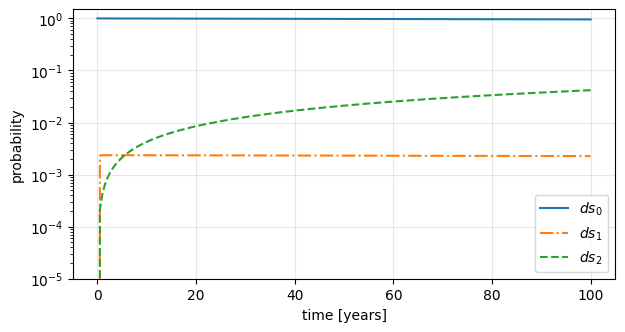

In [3]:
t = np.linspace(0, 100, 201)                    # years
P = np.array([ct.pi_t(Q, ti) for ti in t])      # one row per time step

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, ls in enumerate(['-', '-.', '--']):
    ax.plot(t, P[:, i], ls, label=f"$ds_{i}$")
ax.set_xlabel("time [years]"); ax.set_ylabel("probability")
ax.set_yscale("log"); ax.set_ylim(1e-5, 1.5); ax.legend(); ax.grid(alpha=.3)
plt.show()

The structure spends almost all its time in $ds_0$: damage is rare and repaired quickly.
The probability of collapse $ds_2$ grows slowly and never goes back.

## 3. Reliability: will it collapse within $T_\mathrm{hor}$?

Reliability only needs the **transient block** $Q_\mathcal{T}$ (states $ds_0, ds_1$).
The failure probability $F_\mathcal{T}(t)$ is the probability of reaching $ds_2$ before
$t$ (Eq. 10); the reliability index is $\beta = -\Phi^{-1}(F_\mathcal{T})$ (Eq. 11).

In [4]:
T_hor = 50                       # time horizon [years]
Q_T   = ct.extract_Q_T(Q)        # 2x2 transient block

F, S = ct.F_tau(Q_T, T_hor)
beta = ct.beta_index(F)
print(f"Failure probability in {T_hor} years: F = {F:.4f}")
print(f"Reliability index:                     beta = {beta:.2f}")

Failure probability in 50 years: F = 0.0211
Reliability index:                     beta = 2.03


## 4. Resilience: how much of its life is it functional?

Resilience looks at the time *before* collapse. $\mathcal{R}_0(t)$ is the expected fraction of
time spent **outside** the undamaged state, given that the structure has not collapsed
(Eq. 18): $\mathcal{R}_0 = 0$ means always functional. The resilience index is
$\rho = -\Phi^{-1}(\mathcal{R}_0)$ (Eq. 19): **larger $\rho$ = more resilient**, like $\beta$.

The paper also gives a closed-form **spectral approximation** (Eq. 27), much cheaper and
very accurate when the time horizon is long compared with the repair time:

In [5]:
R0  = ct.R0_exact(Q_T, T_hor)                        # exact (numerical integral)
rho = ct.rho_index(R0)

spec  = ct.spectral_analysis(Q_T)
R0_sp = ct.R0_spectral(spec)                         # spectral approximation

print(f"R0  = {R0:.5f}   (exact)        ->  rho = {rho:.2f}")
print(f"R0  = {R0_sp:.5f}   (spectral, Eq. 27)  ->  rho = {ct.rho_index(R0_sp):.2f}")
print(f"Expected downtime: {R0 * 365:.1f} days per year of life")

R0  = 0.00236   (exact)        ->  rho = 2.83
R0  = 0.00236   (spectral, Eq. 27)  ->  rho = 2.83
Expected downtime: 0.9 days per year of life


## 5. The key message: repair changes resilience, not reliability

Let us change only the median repair time, from one day to two years, and recompute
$\beta$ and $\rho$:

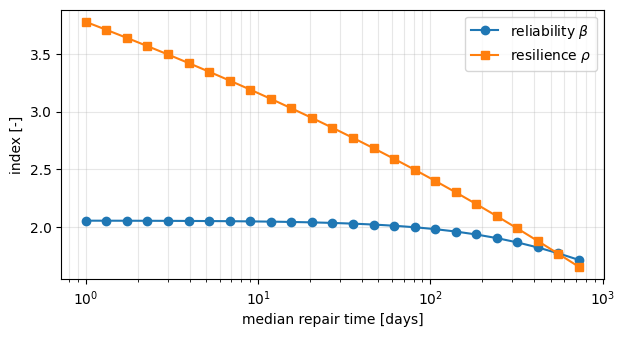

In [6]:
repair_days = np.logspace(0, np.log10(730), 25)
betas, rhos = [], []
for d in repair_days:
    Q_T_d = ct.extract_Q_T(ct.build_Q(lam01, lam02, lam12, mu_from_median_repair(d)))
    betas.append(ct.beta_index(ct.F_tau(Q_T_d, T_hor)[0]))
    rhos.append(ct.rho_index(ct.R0_exact(Q_T_d, T_hor)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(repair_days, betas, 'o-', label=r"reliability $\beta$")
ax.semilogx(repair_days, rhos,  's-', label=r"resilience $\rho$")
ax.set_xlabel("median repair time [days]"); ax.set_ylabel("index [-]")
ax.legend(); ax.grid(alpha=.3, which='both')
plt.show()

Going from 1 day to 2 years of repair, $\beta$ decreases only moderately (from about 2.05 to 1.71:
collapse is governed mainly by the seismic rates), while $\rho$ drops from about 3.8 to 1.7.
The two indices measure different things and should be read together.

## 6. The case study of the paper

The case study compares two buildings at an Italian site: a **braced frame** (BF, `fixed`)
and a **base-isolated** building (BI, `isolated`). The rates are not chosen by hand: they come
from the seismic hazard curve and from state-dependent fragility curves, stored in `data/`.
`generator.build_Q_matrices` turns them into one $Q$ matrix per combination of hazard
quantile, fragility quantile and recovery scenario.

> The case-study data are confidential and not included in the public repository (available
> upon request, see `README.md`). Sections 1–5 above run without them; this section needs them.

In [7]:
# confidential case-study data, available upon request (README, "Data availability")
require_data("SS-input-hazard-fragilities-20260512.pkl")

with open(DATA / "SS-input-hazard-fragilities-20260512.pkl", "rb") as f:
    data_input = pickle.load(f)
print("Content of the input file:", list(data_input.keys()))

# Median recovery times [days] for short ('low') and long ('high') repair (Table 3)
recovery_dict = {
    'fixed':    {'low': 30, 'high': 365},
    'isolated': {'low':  1, 'high':  50},
}

Qsim = generator.build_Q_matrices(
    hazard               = data_input['hazard'],
    hazard_locations     = ['ita'],
    hazard_qtiles        = ['lambda_0.05', 'lambda_0.5', 'lambda_0.95'],
    struct_dicts         = {'fixed':    data_input['pb_transitions_exc_fixed'],
                            'isolated': data_input['pb_transitions_exc_isolated']},
    pb_transition_qtiles = ['p01', 'p05', 'p16', 'p50', 'p84', 'p95', 'p99'],
    recovery_dict        = recovery_dict,
    verbose              = False,
)
# Qsim[site][hazard quantile][structure][fragility quantile][recovery scenario] -> 3x3 Q

Content of the input file: ['hazard', 'pb_transitions_exc_isolated', 'pb_transitions_exc_fixed']


Same analysis as above, for both buildings and both repair scenarios
(settings of Table 5 of the paper: hazard quantile `lambda_0.05`, median fragility `p50`):

In [8]:
rows = []
for structure, label in [('fixed', 'Braced frame'), ('isolated', 'Base-isolated')]:
    for scenario in ['low', 'high']:
        Qc   = Qsim['ita']['lambda_0.05'][structure]['p50'][scenario]
        Q_Tc = ct.extract_Q_T(Qc)
        F_c, _ = ct.F_tau(Q_Tc, T_hor)
        R0_c   = ct.R0_exact(Q_Tc, T_hor)
        rows.append({
            'structure': label,
            'repair [days]': recovery_dict[structure][scenario],
            'mu10 [1/yr]': Qc[1, 0],
            'F (50 yr)': F_c,
            'beta': ct.beta_index(F_c),
            'R0 (50 yr)': R0_c,
            'rho': ct.rho_index(R0_c),
        })

pd.DataFrame(rows).round(4)

,structure,repair [days],mu10 [1/yr],F (50 yr),beta,R0 (50 yr),rho
0,Braced frame,30,8.4333,0.1591,0.9983,0.0062,2.4993
1,Braced frame,365,0.6931,0.1687,0.9595,0.0685,1.4872
2,Base-isolated,1,252.9987,0.0187,2.0816,0.0000,4.1563
3,Base-isolated,50,5.0600,0.0187,2.0813,0.0008,3.1542


These are the values of Table 5 of the paper. The base-isolated building is both more reliable (higher $\beta$) and more resilient
(higher $\rho$). For both buildings, slower repair lowers $\rho$ by about one unit, while $\beta$
changes only marginally.

## Where to go next

| What | Where |
|---|---|
| Figures 3–7 of the paper (toy example) | `notebooks/01_toy_example.ipynb` |
| Case study, all figures and tables | `notebooks/02_case_study.ipynb` |
| Rebuild the input data (hazard + fragilities) | `notebooks/00_build_inputs.ipynb` |
| Check that your figures match the published ones | `python tests/compare_figures.py` |
| Function reference | docstrings: `help(ct.R0_exact)`; user manual (in preparation) |